[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sear-labs/energy-system-modeling/blob/main/notebooks/p4_networks/18_power_flow_and_lmp.ipynb)

# Power flow and locational marginal pricing
## REE 4301 / IE 5300 - Energy Systems Modeling

In the transport companion you moved gas through pipelines. You chose the flow on every route, and the only limits were capacities. That is a **transport model**, and it is the right model for pipelines, railways and shipping.

**Electricity does not work that way.** Nobody chooses how power flows. It divides itself among every available path according to the physics of the network, and the grid operator's only levers are which generators run and what the network is built like.

This notebook does the same thing twice, as always:

1. **In gurobipy**, where you write the power-flow equations yourself and pull the prices out of the LP by hand.
2. **In PyPSA**, where you say `Line` instead of `Link` and all of it happens for you.

The point to carry out of here is one sentence: **a locational marginal price is the dual variable of a nodal balance constraint.** Not an economic theory bolted on afterwards - a number that falls out of the same LP you have been writing since Module 0.


## Setup

One cell, the same in every notebook here: it installs what Colab does not have, fetches this repository so `data/` and `src/` are present, and moves into this notebook's own folder so the relative paths below resolve. The notebook's own imports follow in the same cell.


In [1]:
# --- setup: generated by tools/sync_setup_cells.py -- do not edit here, edit that
# The same cell in every notebook in this series. It installs what Colab does
# not have, fetches the repository so that data/ and src/ are present, and moves
# into this notebook's own folder so the relative paths below resolve.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/sear-labs/energy-system-modeling"
REPO_NAME = REPO_URL.rstrip("/").split("/")[-1]
NOTEBOOK_DIR = "notebooks/p4_networks"

# Pinned, per Part 1 rule 3: an unpinned install will one day pull a major
# version with a changed API and either break or silently alter the answer.
PINS = ["gurobipy>=11,<14", "highspy>=1.11,<2", "pypsa>=1.3,<2"]

if "google.colab" in sys.modules:
    if PINS:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINS], check=True)
    # An ABSOLUTE base, so re-running this cell is safe. Colab's "Run all" is
    # commonly run twice, and a relative check would look for the clone inside
    # the folder it had already moved into -- cloning a second copy nested one
    # level down, then working from the wrong one.
    BASE = Path("/content") if Path("/content").is_dir() else Path.home()
    REPO_DIR = BASE / REPO_NAME
    if not REPO_DIR.exists():
        cloned = subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
            capture_output=True, text=True)
        if cloned.returncode != 0:
            raise SystemExit(
                "Could not clone " + REPO_URL + "\n"
                + (cloned.stderr or "").strip() + "\n\n"
                "If that says 'not found', the repository is still private.\n"
                "A raw file URL fails the same way, so there is no way around\n"
                "it: it has to be public before a student can run this.")
    os.chdir(REPO_DIR / NOTEBOOK_DIR)
elif Path.cwd().name != Path(NOTEBOOK_DIR).name:
    raise SystemExit(
        "Run this notebook from its own folder (" + NOTEBOOK_DIR + "),\n"
        "so that ../../src and ../../data resolve.")

sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
print("working directory:", Path.cwd().name)

# --- end generated setup; the notebook's own imports follow ---



working directory: p4_networks


In [2]:
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import pypsa
import warnings
warnings.filterwarnings('ignore')

SOLVER = 'gurobi'
# SOLVER = 'highs'     # <-- uncomment: open source, no licence, no size cap

# For homework: paste your academic Web License Service key here.
WLS = {}   # {'WLSACCESSID': '...', 'WLSSECRET': '...', 'LICENSEID': 000000}
ENV = gp.Env(params=WLS) if (SOLVER == 'gurobi' and WLS) else None

print(f'solver: {SOLVER}'
      + ('  (academic WLS licence)' if ENV else '  (default licence)'))


solver: gurobi  (default licence)


---
# Part A - The system, and why it needs angles

Three buses in a triangle. Every line has the same reactance, *X* = 0.1.

| bus | what is there | capacity | cost |
|---|---|---|---|
| West Texas | wind | 150 MW | \$0/MWh |
| Houston | gas | 100 MW | \$40/MWh |
| Dallas | 120 MW of demand | - | - |

**The West Texas to Dallas line can carry only 70 MW.** The other two are effectively unlimited.


### First, predict

Wind is free and there is 150 MW of it. Demand is 120 MW. So run 120 MW of wind and pay nothing - except the direct line to Dallas only holds 70.

**Write down your answers before you run anything:**

1. How much wind and how much gas get dispatched?
2. What is the price of electricity at Dallas?

Most people answer 70 wind / 50 gas for the first, and \$40 for the second. Both are wrong, and the reasons they are wrong are the entire content of this notebook.


### The DC power flow equations

A transport model would let you choose each line's flow. Here you cannot. Instead, each bus gets a **voltage angle** *θ*, and the flow on a line is fixed by the angle difference across it:

&nbsp;&nbsp;&nbsp;&nbsp;*F<sub>ij</sub>* = ( *θ<sub>i</sub>* − *θ<sub>j</sub>* ) / *X<sub>ij</sub>*

That single equation is what makes this a power-flow model. The optimiser picks generation; the angles then *determine* every flow at once. You get flow on lines you never asked to use.

Two consequences worth naming now:

- **Only angle differences matter.** Add 5 to every angle and nothing changes. So one bus must be pinned - the **reference** or **slack** bus - or the LP has infinitely many equally good solutions.
- **You cannot route power.** If you want less flow on a path, your only options are to change what generates where, or to change the network's reactances. Part E does the second.


---
# Part B - By hand, in gurobipy

The same five parts as every other model in this course, numbered the same way as the transport companion.

Watch for one thing in Part 5: we **keep** the three nodal balance constraint objects in named variables. Usually you would not bother. Here they are the whole point, because their dual variables are the prices.


In [3]:
# ==========================================
# 1. Sets and Parameters (Data)
# ==========================================
# The instance comes out of data/raw/ rather than being typed here, because
# the package reads those same four files. Nothing else could show that the
# hand-built model below and the packaged one are the same model -- and if
# you edit a value in data/raw/, both sides pick it up and the check at the
# bottom stays green.
from esm.data import table

buses = list(table('dcopf3_buses.csv')['bus'])
gens = table('dcopf3_generators.csv')
lines = table('dcopf3_lines.csv')
loads = table('dcopf3_loads.csv')

print(gens.to_string(index=False))
print()
print(lines.to_string(index=False))

# The model indexes by generator name and by line name, so pull the columns
# into dictionaries keyed the way every constraint below looks them up. The
# printed dictionaries make that index set explicit rather than implied.
demand = dict(zip(loads['bus'], loads['p_set']))            # D_j,  MW
gen_costs = dict(zip(gens['generator'], gens['marginal_cost']))  # c_g,  $/MWh
gen_max = dict(zip(gens['generator'], gens['p_nom']))       # Pbar_g,  MW
line_X = dict(zip(lines['line'], lines['x']))               # X_ij,  p.u.
line_limit = dict(zip(lines['line'], lines['s_nom']))       # Fbar_ij,  MW

print()
print('demand    ', demand)
print('line_limit', line_limit)

# ==========================================
# 2. Model Initialization
# ==========================================
m = gp.Model('3_Bus_DCOPF', env=ENV) if ENV else gp.Model('3_Bus_DCOPF')
m.Params.OutputFlag = 0


generator        bus  marginal_cost  p_nom
 WTX_Wind West Texas            0.0  150.0
  HOU_Gas    Houston           40.0  100.0

   line       bus0       bus1   x  s_nom
WTX_DAL West Texas     Dallas 0.1   70.0
DAL_HOU     Dallas    Houston 0.1 1000.0
HOU_WTX    Houston West Texas 0.1 1000.0

demand     {'Dallas': 120.0}
line_limit {'WTX_DAL': 70.0, 'DAL_HOU': 1000.0, 'HOU_WTX': 1000.0}



In [4]:
# ==========================================
# 3. Decision Variables
# ==========================================
# Generator dispatch (MW)
P_wind = m.addVar(lb=0, ub=gen_max['WTX_Wind'], name='P_wind')
P_gas = m.addVar(lb=0, ub=gen_max['HOU_Gas'], name='P_gas')

# Voltage angles (radians). These are decision variables too, even though
# nobody 'decides' them physically - the LP solves for the angles that
# make the flows consistent with the injections.
theta_wtx = m.addVar(lb=-GRB.INFINITY, name='theta_wtx')
theta_dal = m.addVar(lb=-GRB.INFINITY, name='theta_dal')
theta_hou = m.addVar(lb=-GRB.INFINITY, name='theta_hou')

# REFERENCE BUS: pin one angle to zero.
# DCOPF determines only angle DIFFERENCES, so without this the model has
# infinitely many optimal solutions and the solver may return any of them.
m.addConstr(theta_wtx == 0, 'Ref_Bus')


<gurobi.Constr *Awaiting Model Update*>

In [5]:
# ==========================================
# 4. Objective Function
# ==========================================
m.setObjective(
    gen_costs['WTX_Wind'] * P_wind + gen_costs['HOU_Gas'] * P_gas,
    GRB.MINIMIZE)


In [6]:
# ==========================================
# 5. Constraints
# ==========================================
# --- the DC power flow equation, F_ij = (theta_i - theta_j) / X_ij ---
# These are linear EXPRESSIONS, not new variables: each one is already
# determined by the angles.
Flow_WTX_DAL = (theta_wtx - theta_dal) / line_X['WTX_DAL']
Flow_DAL_HOU = (theta_dal - theta_hou) / line_X['DAL_HOU']
Flow_HOU_WTX = (theta_hou - theta_wtx) / line_X['HOU_WTX']

# --- thermal limit, in BOTH directions ---
m.addConstr(Flow_WTX_DAL <= line_limit['WTX_DAL'], 'Limit_WTX_DAL_Pos')
m.addConstr(Flow_WTX_DAL >= -line_limit['WTX_DAL'], 'Limit_WTX_DAL_Neg')

# --- nodal power balance at every bus (Kirchhoff's current law) ---
# generation - demand = net flow leaving the bus
#
# *** KEEP THESE OBJECTS. Their dual variables are the LMPs. ***
bal_wtx = m.addConstr(
    P_wind - 0 == Flow_WTX_DAL - Flow_HOU_WTX, 'Balance_WTX')
bal_dal = m.addConstr(
    0 - demand['Dallas'] == Flow_DAL_HOU - Flow_WTX_DAL, 'Balance_DAL')
bal_hou = m.addConstr(
    P_gas - 0 == Flow_HOU_WTX - Flow_DAL_HOU, 'Balance_HOU')


In [7]:
# ==========================================
# 6. Optimize and Output
# ==========================================
m.optimize()
assert m.Status == GRB.OPTIMAL, f'solver status {m.Status}'

f_wd = Flow_WTX_DAL.getValue()
f_dh = Flow_DAL_HOU.getValue()
f_hw = Flow_HOU_WTX.getValue()

# Dallas's balance was written with demand on the LEFT, so its dual comes
# out with the opposite sign to the other two. Negate it to get the price.
lmp_wtx, lmp_dal, lmp_hou = bal_wtx.Pi, -bal_dal.Pi, bal_hou.Pi

print('dispatch')
print(f'  wind (West Texas) {P_wind.X:6.1f} MW')
print(f'  gas  (Houston)    {P_gas.X:6.1f} MW')
print()
print('line flows  (positive = in the direction named)')
print(f'  West Texas -> Dallas  {f_wd:6.1f} MW   (limit 70)')
print(f'  Dallas -> Houston     {f_dh:6.1f} MW')
print(f'  Houston -> West Texas {f_hw:6.1f} MW')
print()
print('locational marginal prices  (dual of each nodal balance)')
print(f'  West Texas ${lmp_wtx:6.2f} /MWh')
print(f'  Dallas     ${lmp_dal:6.2f} /MWh')
print(f'  Houston    ${lmp_hou:6.2f} /MWh')
print()
print(f'total generation cost ${m.ObjVal:,.2f} /hr')


dispatch
  wind (West Texas)   90.0 MW
  gas  (Houston)      30.0 MW

line flows  (positive = in the direction named)
  West Texas -> Dallas    70.0 MW   (limit 70)
  Dallas -> Houston      -50.0 MW
  Houston -> West Texas  -20.0 MW

locational marginal prices  (dual of each nodal balance)
  West Texas $  0.00 /MWh
  Dallas     $ 80.00 /MWh
  Houston    $ 40.00 /MWh

total generation cost $1,200.00 /hr


---
# Part C - Read that output again

Three things happened that are worth more than the rest of the notebook.

### 1. The dispatch is not 70 / 50

The direct line is full at 70 MW, but **90 MW of wind is running**, not 70. The extra 20 MW leaves West Texas heading for *Houston*, and reaches Dallas the long way round. Nobody routed it there. The angles did.

That is **loop flow**, and it is the thing a transport model cannot represent. Power on a mesh network uses every path between two points, in proportion to how easy each path is.

### 2. Dallas costs \$80/MWh, and nothing in the system costs \$80

The most expensive generator running is gas at **\$40**. Dallas's price is **twice that**. Before reading on: where can an \$80 price come from when nothing in the system costs \$80?

Ask what it actually costs to deliver one more MW to Dallas. You cannot just send more wind - the direct line is full. Pushing one more MW down that path means the angles have to shift, which pulls flow around the loop as well, and the only way to keep every bus balanced is to **turn gas up by more than one MW while turning wind down**. The system pays \$40 twice over to move one MW. Hence \$80.

This is why prices at a constrained location can exceed every generator's cost - and, in real markets, why they can go **negative** at a location that is exporting into a constraint.

### 3. The prices came out of the constraints, not out of an economic model

`bal_dal.Pi` is a *dual variable*. You did not write a pricing rule. You wrote a cost-minimising LP with a balance constraint at each bus, and the prices were already in there.


In [8]:
# congestion rent: what the operator collects from the price difference
# across a line.  rent = flow x (price at the receiving end
#                              - price at the sending end)
rent_wd = f_wd * (lmp_dal - lmp_wtx)
rent_dh = f_dh * (lmp_hou - lmp_dal)
rent_hw = f_hw * (lmp_wtx - lmp_hou)

print(f'  West Texas -> Dallas  ${rent_wd:9,.2f} /hr')
print(f'  Dallas -> Houston     ${rent_dh:9,.2f} /hr')
print(f'  Houston -> West Texas ${rent_hw:9,.2f} /hr')
print(f'  {"total":21s} ${rent_wd + rent_dh + rent_hw:9,.2f} /hr')

print()
print('Consumers at Dallas pay  ${:,.2f}/hr'.format(120 * lmp_dal))
print('Generators are paid      ${:,.2f}/hr'.format(
      P_wind.X * lmp_wtx + P_gas.X * lmp_hou))
print('The difference is the congestion rent above: it does not go to'
      ' anyone who produced or consumed electricity.')


  West Texas -> Dallas  $ 5,600.00 /hr
  Dallas -> Houston     $ 2,000.00 /hr
  Houston -> West Texas $   800.00 /hr
  total                 $ 8,400.00 /hr

Consumers at Dallas pay  $9,600.00/hr
Generators are paid      $1,200.00/hr
The difference is the congestion rent above: it does not go to anyone who produced or consumed electricity.


> **Exercise C.1.** The congestion rent is collected by the grid operator, not by any generator or consumer. In ERCOT it is paid out to the holders of Congestion Revenue Rights. Who *should* receive it, and what would happen to transmission investment if the answer were 'whoever built the line'?
>
> **Exercise C.2.** Raise the limit from 70 to 80 and re-run. Wind covers all 120 MW, gas shuts off - and every LMP goes to \$0. Explain why the congestion rent vanishes at the same moment.


---
# Part D - The same model in PyPSA, one component at a time

Everything you just wrote by hand - the angle variables, the reference bus, the flow equations, the thermal limits, the nodal balances - is written for you by **one word**: `Line` instead of `Link`.

A `Link` is a controllable transport route. You set its flow. A `Line` is AC transmission, and its flow is decided by physics. That is the entire difference, and it is worth more than any other single fact in this module.


### Step 1: Initialize the network


In [9]:
n = pypsa.Network()

# one snapshot: this is a single-hour problem, exactly like the gurobi one
n.set_snapshots([0])
print(n)


PyPSA Network 'Unnamed Network'


### Step 2: Add the buses

A **Bus** is a place where power balances. Each one becomes exactly the `Balance_*` constraint you wrote by hand in Part B - and each one gets an angle variable and a dual variable, for free.


In [10]:
for b in ['West Texas', 'Dallas', 'Houston']:
    n.add('Bus', b)

print(list(n.buses.index))


['West Texas', 'Dallas', 'Houston']


### Step 3: Add the generators

`p_nom` is the capacity and `marginal_cost` is the running cost. Note `p_nom`, not `p_nom_extendable` - this is a **dispatch** problem. Nothing is being built; we are only deciding what to run.


In [11]:
# Generator.p_nom         maps to the capacity limit Pbar_g
# Generator.marginal_cost maps to the cost coefficient c_g
n.add('Generator', 'WTX_Wind', bus='West Texas',
      p_nom=150, marginal_cost=0)
n.add('Generator', 'HOU_Gas', bus='Houston',
      p_nom=100, marginal_cost=40)

print(n.generators[['bus', 'p_nom', 'marginal_cost']].to_string())


                 bus  p_nom  marginal_cost
name                                      
WTX_Wind  West Texas  150.0            0.0
HOU_Gas      Houston  100.0           40.0


### Step 4: Add the demand

`p_set` is a fixed requirement - the *D* on the right-hand side of the Dallas balance constraint.


In [12]:
# Load.p_set maps to the demand requirement D_j
n.add('Load', 'Dallas_Demand', bus='Dallas', p_set=120)

print(n.loads[['bus', 'p_set']].to_string())


                  bus  p_set
name                        
Dallas_Demand  Dallas  120.0

### Step 5: Add the lines - the step that matters

Two arguments, and they are not interchangeable with anything you used in the transport notebook:

- **`x`** is the reactance. This is what invokes the flow equation. Give PyPSA an `x` and it will create the angle variables, write *F* = (*θ<sub>i</sub>* − *θ<sub>j</sub>*)/*X* for every line, and pin a reference bus. There is no argument for 'please apply Kirchhoff' - `x` *is* that argument.
- **`s_nom`** is the thermal rating, enforced in both directions, exactly like the two `Limit_WTX_DAL_*` constraints you wrote by hand.


In [13]:
# Line.x     maps to the reactance X_ij in F_ij = (theta_i - theta_j)/X_ij
# Line.s_nom maps to the thermal limit Fbar_ij (enforced +/-)
n.add('Line', 'WTX_DAL', bus0='West Texas', bus1='Dallas',
      x=0.1, s_nom=70)          # <-- the bottleneck
n.add('Line', 'DAL_HOU', bus0='Dallas', bus1='Houston',
      x=0.1, s_nom=1000)
n.add('Line', 'HOU_WTX', bus0='Houston', bus1='West Texas',
      x=0.1, s_nom=1000)

print(n.lines[['bus0', 'bus1', 'x', 's_nom']].to_string())


               bus0        bus1    x   s_nom
name                                        
WTX_DAL  West Texas      Dallas  0.1    70.0
DAL_HOU      Dallas     Houston  0.1  1000.0
HOU_WTX     Houston  West Texas  0.1  1000.0


### Step 6: Look at what PyPSA is about to solve

Before solving, ask it what it wrote. Compare this list against the constraints you typed in Part B.


In [14]:
lp = n.optimize.create_model()

print('variables:  ', list(lp.variables))
print()
print('constraints:', list(lp.constraints))


Index(['West Texas', 'Dallas', 'Houston'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


variables:   ['Generator-p', 'Line-s']

constraints: ['Generator-fix-p-lower', 'Generator-fix-p-upper', 'Line-fix-s-lower', 'Line-fix-s-upper', 'Bus-nodal_balance', 'Kirchhoff-Voltage-Law']


`Bus-nodal_balance` is your three `Balance_*` constraints. `Line-fix-s_nom-upper` and `-lower` are your two thermal limits. And `Kirchhoff-Voltage-Law` is the one you had to derive angles for.

Notice what PyPSA did *not* need: an explicit angle variable per bus. For a network this small it solves an equivalent formulation over the network's independent loops - one KVL constraint per loop instead of one angle per bus. Same physics, same answer, fewer variables. Another reminder that the tool is doing bookkeeping you could do yourself, but would rather not.


### Step 7: Solve, and read the prices off the buses


In [15]:
n.optimize(solver_name=SOLVER, env=ENV)

out = pd.DataFrame({
    'dispatch MW': n.generators_t.p.iloc[0],
})
print(out.to_string())
print()
print('line flows (MW, positive = bus0 -> bus1)')
print(n.lines_t.p0.iloc[0].round(1).to_string())
print()
print('locational marginal prices ($/MWh)')
print(n.buses_t.marginal_price.iloc[0].round(2).to_string())
print()
print(f'total generation cost ${n.objective:,.2f} /hr')


Index(['West Texas', 'Dallas', 'Houston'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


Index(['0'], dtype='object', name='name')


INFO:linopy.model: Solve problem using Gurobi solver


...

Optimal objective  1.200000000e+03


INFO:gurobipy:Optimal objective  1.200000000e+03


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 5 primals, 14 duals
Objective: 1.20e+03
Solver: gurobi
Runtime: 0.02s
Dual bound: 1.20e+03
Solver model: available
Solver message: 2



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.


          dispatch MW
name                 
WTX_Wind         90.0
HOU_Gas          30.0

line flows (MW, positive = bus0 -> bus1)
name
WTX_DAL    70.0
DAL_HOU   -50.0
HOU_WTX   -20.0

locational marginal prices ($/MWh)
name
West Texas     0.0
Dallas        80.0
Houston       40.0

total generation cost $1,200.00 /hr


### The check that makes the point

`bal_dal.Pi` in your hand-written Gurobi model and `n.buses_t.marginal_price['Dallas']` in PyPSA are **the same number**, because they are the same dual variable of the same constraint.


In [16]:
# The tolerance is imported, not typed. Part 4: a threshold written in two
# places is a value with copies, and the duplicate is where a fix does not
# reach.
from esm.tolerance import agree

py_lmp = n.buses_t.marginal_price.iloc[0]
py_gen = n.generators_t.p.iloc[0]

rows = [
    ('wind MW', P_wind.X, py_gen['WTX_Wind']),
    ('gas MW', P_gas.X, py_gen['HOU_Gas']),
    ('LMP West Texas', lmp_wtx, py_lmp['West Texas']),
    ('LMP Dallas', lmp_dal, py_lmp['Dallas']),
    ('LMP Houston', lmp_hou, py_lmp['Houston']),
    ('total cost', m.ObjVal, n.objective),
]

print(f'{"quantity":16s} {"gurobipy":>12s} {"PyPSA":>12s}  match')
for label, a, b in rows:
    ok = 'yes' if abs(a - b) < 1e-6 else 'NO'
    print(f'{label:16s} {a:12.2f} {b:12.2f}  {ok}')

assert all(agree(a, b) for _, a, b in rows), 'the two models differ'
print()
print('Same model. PyPSA did not invent new mathematics -'
      ' it wrote your constraints for you.')


quantity             gurobipy        PyPSA  match
wind MW                 90.00        90.00  yes
gas MW                  30.00        30.00  yes
LMP West Texas           0.00         0.00  yes
LMP Dallas              80.00        80.00  yes
LMP Houston             40.00        40.00  yes
total cost            1200.00      1200.00  yes

Same model. PyPSA did not invent new mathematics - it wrote your constraints for you.


---
# Part E - Where does the loop flow go?

You saw 20 MW take the long way round at a 70 MW limit. That number is not a coincidence - for this network you can work it out in closed form. With all three reactances equal, the flow on Houston to West Texas is exactly

&nbsp;&nbsp;&nbsp;&nbsp;*F<sub>HW</sub>* = 120 − 2*L*

where *L* is the limit on the West Texas to Dallas line.

**Predict before running:** at what limit does the loop flow disappear entirely? And what happens above that?

One of the five rows below will not solve at all. Before you run it, work out which one and why - it is an arithmetic question about the gas plant, not about the network.


In [17]:
rows = []
for limit in [40, 50, 60, 70, 80]:
    k = pypsa.Network()
    k.set_snapshots([0])
    for b in ['West Texas', 'Dallas', 'Houston']:
        k.add('Bus', b)
    k.add('Generator', 'WTX_Wind', bus='West Texas',
          p_nom=150, marginal_cost=0)
    k.add('Generator', 'HOU_Gas', bus='Houston',
          p_nom=100, marginal_cost=40)
    k.add('Load', 'Dallas_Demand', bus='Dallas', p_set=120)
    k.add('Line', 'WTX_DAL', bus0='West Texas', bus1='Dallas',
          x=0.1, s_nom=limit)
    k.add('Line', 'DAL_HOU', bus0='Dallas', bus1='Houston',
          x=0.1, s_nom=1000)
    k.add('Line', 'HOU_WTX', bus0='Houston', bus1='West Texas',
          x=0.1, s_nom=1000)
    status, condition = k.optimize(solver_name=SOLVER, env=ENV)

    if condition != 'optimal':
        # not a bug - see the note below the table
        rows.append({'limit MW': limit, 'wind MW': None, 'gas MW': None,
                     'HOU->WTX MW': None, 'LMP Dallas': None,
                     'cost $/hr': None, 'status': 'CANNOT SOLVE'})
        print(f'  limit {limit} MW: solver said {condition!r}')
        continue

    g = k.generators_t.p.iloc[0]
    f = k.lines_t.p0.iloc[0]
    p = k.buses_t.marginal_price.iloc[0]
    rows.append({'limit MW': limit,
                 'wind MW': round(g['WTX_Wind'], 1),
                 'gas MW': round(g['HOU_Gas'], 1),
                 'HOU->WTX MW': round(f['HOU_WTX'], 1),
                 'LMP Dallas': round(p['Dallas'], 2),
                 'cost $/hr': round(k.objective, 2),
                 'status': 'optimal'})

sweep = pd.DataFrame(rows).set_index('limit MW')
print(sweep.to_string())


Index(['West Texas', 'Dallas', 'Houston'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


INFO:linopy.model: Solve problem using Gurobi solver


INFO:linopy.io: Writing time: 0.04s


...

Optimal objective  0.000000000e+00


INFO:gurobipy:Optimal objective  0.000000000e+00


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 5 primals, 14 duals
Objective: 0.00e+00
Solver: gurobi
Runtime: 0.01s
Dual bound: 0.00e+00
Solver model: available
Solver message: 2



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.


          wind MW  gas MW  HOU->WTX MW  LMP Dallas  cost $/hr        status
limit MW                                                                   
40            NaN     NaN          NaN         NaN        NaN  CANNOT SOLVE
50           30.0    90.0         20.0        80.0     3600.0       optimal
60           60.0    60.0          0.0        80.0     2400.0       optimal
70           90.0    30.0        -20.0        80.0     1200.0       optimal
80          120.0     0.0        -40.0         0.0        0.0       optimal


### Where exactly does it break?

The sweep says somewhere between 40 and 50 MW. The formula says exactly where: gas has to cover 240 - 3*L*, and the plant is 100 MW, so Dallas can be served only while 240 - 3*L* <= 100.


In [18]:
# Computed and printed rather than stated in the prose above, so the number
# comes from a run. The assert is the point: it fails if a future edit moves
# the sweep, the plant size or the formula out of step with each other.
breakpoint_mw = (240 - 100) / 3
feasible = sweep[sweep['status'] == 'optimal'].index.min()
infeasible = sweep[sweep['status'] != 'optimal'].index.max()

print(f'Dallas can be served only while L >= {breakpoint_mw:.1f} MW')
print(f'the sweep brackets it: {infeasible:.0f} MW infeasible, {feasible:.0f} MW feasible')

assert infeasible < breakpoint_mw < feasible, (
    'the sweep no longer brackets the breakpoint')


Dallas can be served only while L >= 46.7 MW
the sweep brackets it: 40 MW infeasible, 50 MW feasible


> **The row that would not solve.** The cell above printed the breakpoint. Did any number about the wind farm enter it? What would you have to change to serve Dallas at a 40 MW limit?
>
> **Read the `HOU->WTX` column against 120 − 2*L*.** Which way does power run through Houston below 60 MW, and which way above? Who is supplying whom in each case?
>
> **Exercise E.1.** At a 60 MW limit, a transport model and a power-flow model give the same answer. Explain why that is a coincidence and not a reassurance. What would you have concluded about this network if 60 MW were the only case you had ever tested?
>
> **Exercise E.2.** The Dallas LMP column changes with the limit. At which limit does congestion pricing switch off, and what is the price then?


---
# Part F - Reactance steers power

Everything so far used *X* = 0.1 on all three lines. Now change **only** the reactance of the Houston to West Texas line - the loop path - and leave every capacity exactly as it was.

**Predict first.** The direct West Texas to Dallas line is already full at 70 MW and stays full in every case below. So making the loop path easier or harder cannot move power onto the direct route. What does it change?

**This is the lever a transmission planner actually has.** You cannot tell power where to go, but you can change how hard each path is - by building a parallel line, by choosing a conductor, by switching a series device in or out.


In [19]:
rows = []
for label, x_hw in [('easier loop  X=0.05', 0.05),
                    ('base         X=0.10', 0.10),
                    ('harder loop  X=0.20', 0.20)]:
    k = pypsa.Network()
    k.set_snapshots([0])
    for b in ['West Texas', 'Dallas', 'Houston']:
        k.add('Bus', b)
    k.add('Generator', 'WTX_Wind', bus='West Texas',
          p_nom=150, marginal_cost=0)
    k.add('Generator', 'HOU_Gas', bus='Houston',
          p_nom=100, marginal_cost=40)
    k.add('Load', 'Dallas_Demand', bus='Dallas', p_set=120)
    k.add('Line', 'WTX_DAL', bus0='West Texas', bus1='Dallas',
          x=0.1, s_nom=70)
    k.add('Line', 'DAL_HOU', bus0='Dallas', bus1='Houston',
          x=0.1, s_nom=1000)
    k.add('Line', 'HOU_WTX', bus0='Houston', bus1='West Texas',
          x=x_hw, s_nom=1000)
    k.optimize(solver_name=SOLVER, env=ENV)

    g = k.generators_t.p.iloc[0]
    f = k.lines_t.p0.iloc[0]
    p = k.buses_t.marginal_price.iloc[0]
    rows.append({'scenario': label,
                 'wind MW': round(g['WTX_Wind'], 1),
                 'gas MW': round(g['HOU_Gas'], 1),
                 'WTX->DAL MW': round(f['WTX_DAL'], 1),
                 'HOU->WTX MW': round(f['HOU_WTX'], 1),
                 'LMP Dallas': round(p['Dallas'], 2),
                 'cost $/hr': round(k.objective, 2)})

print(pd.DataFrame(rows).set_index('scenario').T.to_string())


Index(['West Texas', 'Dallas', 'Houston'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


Index(['WTX_DAL', 'DAL_HOU', 'HOU_WTX'], dtype='object', name='name')


INFO:linopy.model: Solve problem using Gurobi solver


INFO:linopy.io: Writing time: 0.03s


...

Optimal objective  1.600000000e+03


INFO:gurobipy:Optimal objective  1.600000000e+03


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 5 primals, 14 duals
Objective: 1.60e+03
Solver: gurobi
Runtime: 0.02s
Dual bound: 1.60e+03
Solver model: available
Solver message: 2



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Line-fix-s-lower, Line-fix-s-upper, Kirchhoff-Voltage-Law were not assigned to the network.


scenario     easier loop  X=0.05  base         X=0.10  harder loop  X=0.20
wind MW                    110.0                 90.0                 80.0
gas MW                      10.0                 30.0                 40.0
WTX->DAL MW                 70.0                 70.0                 70.0
HOU->WTX MW                -40.0                -20.0                -10.0
LMP Dallas                 120.0                 80.0                 60.0
cost $/hr                  400.0               1200.0               1600.0


### Read that table carefully - it contains a trap

**`WTX->DAL` is 70 MW in all three columns.** The direct line is full regardless. So what actually changed is the *loop*: 40, 20, then 10 MW. Easier loop path, more wind reaches Dallas the long way - 110 MW, 90 MW, 80 MW - and gas covers whatever wind cannot deliver.

**Total cost goes \$400, \$1,200, \$1,600.** Nobody built or removed a single MW of capacity. The only thing that changed was how hard one path is.

Now the trap. Look at the Dallas LMP: **\$120, \$80, \$60.** The price is *highest* in the cheapest system and *lowest* in the most expensive one. That is not an error.

For this network the relationship is exact:

&nbsp;&nbsp;&nbsp;&nbsp;LMP<sub>Dallas</sub> = LMP<sub>Houston</sub> × ( 1 + *X*<sub>WD</sub> / *X*<sub>HW</sub> )

Check it: 40 × (1 + 0.1/0.05) = 120. 40 × (1 + 0.1/0.1) = 80. 40 × (1 + 0.1/0.2) = 60.

The easier the loop path, the more leverage one extra MW at Dallas has over the whole system - so the *marginal* price climbs even as the *total* bill falls. Before the exercises: if someone asks whether this system is doing well, which of those two numbers answers them?

> **Exercise F.1.** You are a planner trying to relieve congestion on the West Texas to Dallas line, and you have budget for exactly one project. Would you (a) build a second parallel West Texas to Dallas line, or (b) upgrade the Houston to West Texas line to lower its reactance? Use the table to argue for one, then test the other by editing the cell above.
>
> **Exercise F.2.** A generator developer is choosing where to site a new plant and picks Dallas because its LMP is the highest on the system. Using the X=0.05 column, explain why that reasoning is dangerous.
>
> **Exercise F.3 - the one worth putting in a report.** A new data centre opens at Dallas and demand rises from 120 MW to 200 MW. Is the system still feasible with the 70 MW limit? Find the largest Dallas demand this network can serve, and say which constraint stops it.


---
*Before class: the price at the constrained bus rose above every generator's cost. If you were siting a large load, would you rather sit there or at the cheap bus - and what would your arrival do to the price you picked it for?*

### Sources
- DC power-flow approximation and the reference-bus requirement: any power-systems text; see also the PyPSA docs on `Line` and `Kirchhoff-Voltage-Law`.
- ERCOT nodal prices and Congestion Revenue Rights: ercot.com market information.
- The \$22.14/MWh delivered gas figure used elsewhere in this course is built in the SB6 notebook; the \$40/MWh here is a round number chosen to make the arithmetic checkable by hand.


---
## Does the package agree?

Everything above was built by hand, one constraint at a time, because that is the lesson. `esm.power_flow` builds the same model once, from the same four tables in `data/raw/`, through PyPSA rather than through gurobipy.

Two transcriptions of the same algebra would share their mistakes, so the package deliberately takes a different route to the same model. If the two agree, the hand-built version above is probably right.

**What is compared, and what is not.** The voltage angles are *not* unique - DC power flow fixes only angle differences, so this notebook's reference bus, PyPSA's, and the package's all give different angles and all three are correct. Flows, dispatch, prices and cost are the same in every optimum, so those are what the check asserts. Comparing the angles would be checking that two solvers took the same path, which is not the same claim at all.


In [20]:
from esm.power_flow import load_dcopf3, solve_dcopf, check_balances
from esm.tolerance import AGREEMENT_RTOL, relative

packaged = solve_dcopf(load_dcopf3())

checks = [('total cost', m.ObjVal, packaged.cost),
          ('wind MW', P_wind.X, packaged.dispatch['WTX_Wind']),
          ('gas MW', P_gas.X, packaged.dispatch['HOU_Gas']),
          ('flow WTX->DAL', f_wd, packaged.flows['WTX_DAL']),
          ('flow DAL->HOU', f_dh, packaged.flows['DAL_HOU']),
          ('LMP West Texas', lmp_wtx, packaged.lmp['West Texas']),
          ('LMP Dallas', lmp_dal, packaged.lmp['Dallas']),
          ('LMP Houston', lmp_hou, packaged.lmp['Houston'])]

print(f'{'quantity':16s} {'by hand':>12s} {'package':>12s} {'rel diff':>10s}')
for label, hand, pkg in checks:
    print(f'{label:16s} {hand:12.4f} {pkg:12.4f} {relative(hand, pkg):10.1e}')

worst = max(relative(a, b) for _, a, b in checks)
assert worst < AGREEMENT_RTOL, (
    f'notebook and package disagree by {worst:.2e}, '
    f'which is worse than {AGREEMENT_RTOL:.0e}')

# And a domain invariant, asserted rather than asserted-in-prose: every bus
# balances. If this fails the plumbing is wrong, not the physics.
check_balances(load_dcopf3(), packaged)

print()
print(f'notebook and package agree to {worst:.1e}; every bus balances')


quantity              by hand      package   rel diff
total cost          1200.0000    1200.0000    0.0e+00
wind MW               90.0000      90.0000    0.0e+00
gas MW                30.0000      30.0000    0.0e+00
flow WTX->DAL         70.0000      70.0000    0.0e+00
flow DAL->HOU        -50.0000     -50.0000    0.0e+00
LMP West Texas         0.0000      -0.0000    0.0e+00
LMP Dallas            80.0000      80.0000    0.0e+00
LMP Houston           40.0000      40.0000    0.0e+00

notebook and package agree to 0.0e+00; every bus balances


---
## Explore - for your reflection

Nothing above changes. The slider cells redraw when you let go of a slider; the **edit-and-run** cells ask you to write a line or two of model code yourself. Answer the numbered questions in your reflection.

### Now the streamlined version

From here the model is wrapped in functions, because a slider re-runs it every time it moves - and you have built every piece of it by hand above. This first cell only quiets the solver, which the sliders call often.


In [21]:
from ipywidgets import interact, fixed, FloatSlider
import logging
for name in ('pypsa', 'linopy'):
    logging.getLogger(name).setLevel(logging.ERROR)
# the sliders re-solve often: one silent solver set-up, no log per solve
if SOLVER == 'gurobi':
    QUIET = {'env': gp.Env(params={**WLS, 'OutputFlag': 0}), 'io_api': 'direct'}
else:
    QUIET = {'log_to_console': False}


### Slide it: what reactance does to the current

One AC circuit: a 120 V, 60 Hz source driving a resistor *R*, a coil *X<sub>L</sub>* and a capacitor *X<sub>C</sub>* in a row, all in ohms. The top plot shows voltage and current, each scaled to its own peak. The bottom one is their product, the power delivered at each instant, with its average marked.


In [22]:
import matplotlib.pyplot as plt

def ac(R=1.0, X_L=10.0, X_C=0.0):
    """Series R, coil and capacitor on a 120 V rms, 60 Hz source."""
    Z = complex(R, X_L - X_C)        # impedance, ohms
    phi = np.angle(Z)                # + : current lags, - : current leads
    I = 120 / abs(Z)                 # rms amps
    t = np.linspace(0, 2 / 60, 500)  # two cycles, seconds
    w = 2 * np.pi * 60
    v = np.sin(w * t)
    i = np.sin(w * t - phi)
    p = (120 * np.sqrt(2) * v) * (I * np.sqrt(2) * i)
    P, Q = 120 * I * np.cos(phi), 120 * I * np.sin(phi)
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    top.plot(t * 1000, v, label='voltage')
    top.plot(t * 1000, i, '--', label='current')
    top.set_ylabel('fraction of peak')
    top.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
    bottom.plot(t * 1000, p, color='C2', label='power at each instant')
    bottom.axhline(P, color='C2', ls=':', label='average = P')
    bottom.axhline(0, color='black', lw=0.6)
    bottom.set_ylabel('W')
    bottom.set_xlabel('milliseconds')
    bottom.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
    ALT_TEXT = (f'Two stacked plots over two 60 Hz cycles. Top: voltage and current, '
                f'the current shifted {np.degrees(phi):+.0f} degrees. Bottom: power at '
                f'each instant, averaging P = {P:,.0f} W.')
    plt.show()
    print(f'|Z| = {abs(Z):.1f} ohm    current {I:.1f} A rms    '
          f'current shifted {np.degrees(phi):+.0f} degrees from voltage')
    print(f'P = {P:,.0f} W    Q = {Q:,.0f} var')

interact(ac,
    R=FloatSlider(min=0.5, max=20, step=0.5, value=1.0, description='R ohm',
                  continuous_update=False),
    X_L=FloatSlider(min=0, max=20, step=0.5, value=10.0, description='coil X_L',
                    continuous_update=False),
    X_C=FloatSlider(min=0, max=20, step=0.5, value=0.0, description='capacitor X_C',
                    continuous_update=False));


interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='R ohm', max=20.0, min=0.5, …

> **1.** Set the coil and the capacitor to 0. Where do the current's peaks sit relative to the voltage's? Does the power curve ever go below zero?
>
> **2.** Now *R* = 1 and *X<sub>L</sub>* = 10, roughly the ratio on a high-voltage transmission line. How far is the current shifted? For what part of each cycle is power flowing *back* into the source, and which of *P* and *Q* measures that back-and-forth? Which of the two does a DC power flow keep?
>
> **3.** Keep *X<sub>L</sub>* at 10 and raise the capacitor until the current is back in step with the voltage. What *X<sub>C</sub>* did it take, and what happened to *Q* and to the current? Utilities install capacitor banks on their lines: what would you guess they are for?

### Slide it: the three-bus grid

Part D's network, redrawn every time you let go of a slider. Each bus shows its price; each line shows which way power runs and how much, against its limit, and is marked **FULL** when it is at that limit. The title gives the total cost and the congestion rent.


In [23]:
POS = {'West Texas': (0.0, 0.0), 'Dallas': (2.0, 1.2), 'Houston': (2.0, -1.2)}
UNDER = {'West Texas': -0.45, 'Dallas': 0.45, 'Houston': -0.45}

def solve_grid(limit=70, x_loop=0.1, demand=120, extra=None):
    """Part D's network with your numbers. extra(k), if given, changes the
    network before the solve. Returns the solved network, or None."""
    k = pypsa.Network()
    k.set_snapshots([0])
    for b in POS:
        k.add('Bus', b)
    k.add('Generator', 'WTX_Wind', bus='West Texas', p_nom=150, marginal_cost=0)
    k.add('Generator', 'HOU_Gas', bus='Houston', p_nom=100, marginal_cost=40)
    k.add('Load', 'Dallas_Demand', bus='Dallas', p_set=demand)
    k.add('Line', 'WTX_DAL', bus0='West Texas', bus1='Dallas', x=0.1, s_nom=limit)
    k.add('Line', 'DAL_HOU', bus0='Dallas', bus1='Houston', x=0.1, s_nom=1000)
    k.add('Line', 'HOU_WTX', bus0='Houston', bus1='West Texas', x=x_loop, s_nom=1000)
    if extra is not None:
        extra(k)
    status, condition = k.optimize(solver_name=SOLVER, **QUIET)
    return k if condition == 'optimal' else None


The drawing comes in two pieces. `draw_lines` draws each line with its flow, limit and direction, and adds up the congestion rent as it goes: each line's flow times the price difference across it.


In [24]:
def draw_lines(ax, k, lmp):
    """Every Line and Link: thicker with flow, red when full. Returns the rent."""
    # alt: no figure of its own; draw() below sets ALT_TEXT for the whole picture
    branches = [(nm, r.bus0, r.bus1, k.lines_t.p0.iloc[0][nm], r.s_nom, '-')
                for nm, r in k.lines.iterrows()]
    branches += [(nm, r.bus0, r.bus1, k.links_t.p0.iloc[0][nm], r.p_nom, '--')
                 for nm, r in k.links.iterrows()]
    rent, seen = 0.0, {}
    for nm, b0, b1, flow, cap, style in branches:
        rent += flow * (lmp[b1] - lmp[b0])
        pair = frozenset((b0, b1))
        shift = 0.22 * seen.get(pair, 0)       # parallel branches sit side by side
        seen[pair] = seen.get(pair, 0) + 1
        (x0, y0), (x1, y1) = POS[b0], POS[b1]
        length = ((x1 - x0) ** 2 + (y1 - y0) ** 2) ** 0.5
        px, py = -(y1 - y0) / length, (x1 - x0) / length
        x0, y0, x1, y1 = x0 + px * shift, y0 + py * shift, x1 + px * shift, y1 + py * shift
        full = cap < 1000 and abs(flow) >= cap - 0.01
        colour = '#b03a2e' if full else '#4d4d4d'
        ax.plot([x0, x1], [y0, y1], style, color=colour, lw=1.5 + abs(flow) / 12, zorder=1)
        mx, my = (x0 + x1) / 2, (y0 + y1) / 2
        if abs(flow) > 0.05:
            sign = 1 if flow > 0 else -1
            dx, dy = sign * (x1 - x0) * 0.08, sign * (y1 - y0) * 0.08
            ax.annotate('', xy=(mx + dx, my + dy), xytext=(mx - dx, my - dy), zorder=3,
                        arrowprops=dict(arrowstyle='-|>', color=colour, lw=2,
                                        mutation_scale=24))
        label = f'{abs(flow):.0f} MW' if cap >= 1000 else f'{abs(flow):.0f} of {cap:.0f} MW'
        side = 'left' if px > 0.3 else 'right' if px < -0.3 else 'center'
        ax.text(mx + px * 0.16, my + py * 0.16, label + ('  FULL' if full else ''),
                ha=side, va='center', fontsize=10, color=colour,
                fontweight='bold' if full else 'normal')
    return rent


Then the buses, each coloured by its price, and the slider. `grid` solves first and draws only if some dispatch serves the load.


In [25]:
def draw(k):
    lmp = k.buses_t.marginal_price.iloc[0]
    fig, ax = plt.subplots(figsize=(9, 6))
    rent = draw_lines(ax, k, lmp)
    for b, (x, y) in POS.items():
        ax.scatter([x], [y], s=2800, c=[lmp[b]], cmap='YlOrRd', vmin=0,
                   vmax=1.6 * max(150.0, float(lmp.max())), edgecolors='black', zorder=4)
        ax.text(x, y, f'{b}\n${lmp[b]:.0f}/MWh', ha='center', va='center',
                fontsize=9, fontweight='bold', zorder=5, parse_math=False)
        here = [f'{g}: {k.generators_t.p.iloc[0][g]:.0f} of {r.p_nom:.0f} MW'
                for g, r in k.generators.iterrows() if r.bus == b]
        here += [f'{d}: {r.p_set:.0f} MW' for d, r in k.loads.iterrows() if r.bus == b]
        ax.text(x, y + UNDER[b], '\n'.join(here), ha='center', fontsize=9,
                va='top' if UNDER[b] < 0 else 'bottom')
    ax.set_title(f'total cost ${k.objective:,.0f}/hr      '
                 f'congestion rent ${rent:,.0f}/hr', parse_math=False)
    ax.set_xlim(-1.0, 3.1)
    ax.set_ylim(-2.1, 2.1)
    ax.set_aspect('equal')
    ax.axis('off')
    ALT_TEXT = ('Three-bus triangle; bus prices ' + ', '.join(f'{b} ${lmp[b]:.0f}/MWh' for b in POS)
                + '; line flows ' + ', '.join(f'{nm} {f:+.0f} MW' for nm, f in k.lines_t.p0.iloc[0].items()))
    plt.show()

def grid(limit=70, x_loop=0.1, demand=120, extra=None):
    k = solve_grid(limit, x_loop, demand, extra)
    if k is None:
        print(f'No dispatch serves {demand:.0f} MW at Dallas with a {limit:.0f} MW '
              'West Texas to Dallas line: the solver reports the problem infeasible.')
        return
    draw(k)

interact(grid,
    limit=FloatSlider(min=30, max=150, step=5, value=70,
                      description='WTX-DAL MW', continuous_update=False),
    x_loop=FloatSlider(min=0.05, max=0.30, step=0.05, value=0.10,
                       description='X HOU-WTX', continuous_update=False),
    demand=FloatSlider(min=60, max=220, step=10, value=120,
                       description='Dallas MW', continuous_update=False),
    extra=fixed(None));


interactive(children=(FloatSlider(value=70.0, continuous_update=False, description='WTX-DAL MW', max=150.0, mi…

> **4.** Start the limit at 150 MW and slide it down in steps of 5. At what limit do the three prices first split apart? Before you get there, predict it from how the 120 MW divides between the two paths when nothing binds.
>
> **5.** Keep going down. Which way does power run on the Houston to West Texas line at 75 MW, and at 50 MW? At what limit does the picture stop drawing? Leave it there and try the other two sliders, one at a time. Which brings the picture back, and in which direction did you have to move it? Is that the direction you expected?
>
> **6.** Put the limit at 70 and the reactance at 0.10, then raise Dallas demand 10 MW at a time. What is the largest demand this grid serves, and which piece of equipment runs out first? Check it by hand with Part E's gas formula, rewritten for any demand.

### Edit and run: build the parallel line

Exercise F.1 asked whether to build a second West Texas to Dallas line or make the loop path easier. Test the first. Inside `parallel_line`, write one `k.add('Line', ...)`: a second West Texas to Dallas line with the same `x` and `s_nom` as the first, under a new name. `grid` runs it before the solve.


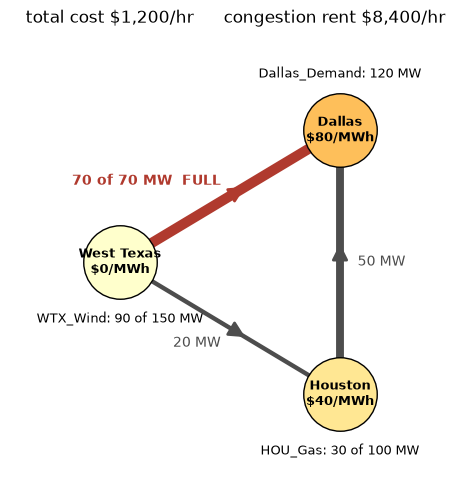

In [26]:
def parallel_line(k):
    # your one line of model code
    pass

grid(limit=70, extra=parallel_line)


> **7.** Before you run it: will each direct line carry 70 MW? Run it. Then set the slider above to option (b), reactance 0.05 at a 70 MW limit. Which project relieved the congestion, and what in the picture told you without reading the numbers?

### Edit and run: replace the line with a DC link

A `Link` carries the flow you set; a `Line` carries the flow the angles set. Swap the AC line for a DC link of the same 70 MW. Two lines of code: `k.remove('Line', 'WTX_DAL')`, then a `k.add('Link', ...)` from West Texas to Dallas with `p_nom=70` and `marginal_cost=0.5`, what the converter stations charge per MWh. Left at its default, a `Link` runs one way only, bus0 to bus1.


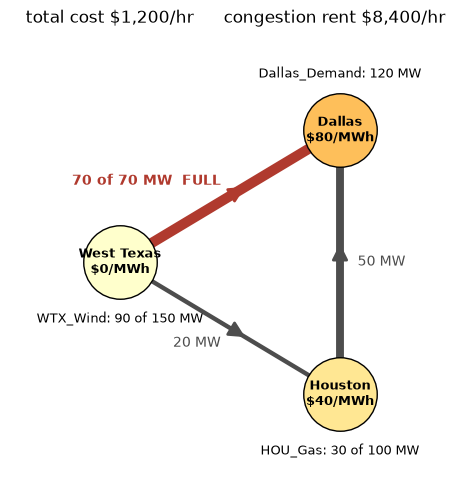

In [27]:
def dc_link(k):
    # your two lines of model code
    pass

grid(limit=70, extra=dc_link)


> **8.** The direct route has exactly the capacity it had in Part B. Before you run it: does the gas plant still run? After: what is the Houston path doing now? Was the 70 MW limit, on its own, what forced gas on in Part B?

### Edit and run: put solar at Dallas

Write your own `dallas_solar(k)` that adds a zero-cost generator at Dallas, and call `grid(limit=70, extra=dallas_solar)`. Start at 40 MW.


In [28]:
# def dallas_solar(k):
#     ...
#
# grid(limit=70, extra=dallas_solar)


> **9.** What does 40 MW at Dallas do to every price? Shrink it until Dallas's price comes back. How small a plant at the load does the same job as the parallel line in question 7, and why so much smaller than the line?
